# 1 — Gerçek ve sahte seslerde STFT, Mel ve CQT
**Çalıştırma:** `.venv` kernel'ini seçin; dosya listesini çalıştırıp seçim hücresini düzenleyin.
Gerçek sesleri `data/raw/gercek`, sahte sesleri `data/raw/sahte` içine kopyalayın.
Her dönüşüm için iki kayıtta ortak renk referansı ve aynı parametreler kullanılır. Dönüşümler arası renk/genlik doğrudan karşılaştırılmaz.
Etiketler dosyalarınızdan gelir; grafikler sahte ses kararı veren bir algılayıcı değildir.
Aynı konuşmacı, metin ve kayıt koşullarına sahip eşleşmeler daha anlamlıdır. Codec ve mikrofon farkları da iz bırakabilir.

In [1]:
from pathlib import Path
from datetime import datetime
import sys
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
from IPython.display import Audio, display

PROJE = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
              if (p / 'src').is_dir() and (p / 'data/raw').is_dir()), None)
if PROJE is None:
    raise FileNotFoundError('VS Code ile ses-analizi proje klasörünü açın.')
if str(PROJE / 'src') not in sys.path:
    sys.path.insert(0, str(PROJE / 'src'))
from ses_arastirma import (audio_files, read_audio, save_csv, save_json, sha256,
                          ffmpeg_exe, ffmpeg_run, mdct, align_to_reference,
                          low_energy_intervals, interval_psd)
RUN = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
print('Python:', sys.executable)
print('Proje:', PROJE)

Python: /Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/.venv/bin/python
Proje: /Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi


## Dosyaları listele

In [ ]:
for etiket in ['gercek', 'sahte']:
    print('\n', etiket.upper())
    for dosya in audio_files(PROJE / 'data/raw' / etiket): # type: ignore
        print(dosya.relative_to(PROJE)) # type: ignore


 GERCEK
data/raw/gercek/gercek_01_LA_E_7781360.flac
data/raw/gercek/gercek_02_LA_D_2042159.flac
data/raw/gercek/gercek_03_LA_D_3354668.flac
data/raw/gercek/gercek_04_LA_E_1351470.flac
data/raw/gercek/gercek_05_LA_D_9924906.flac
data/raw/gercek/gercek_06_LA_D_1519237.flac
data/raw/gercek/gercek_07_LA_E_4174184.flac
data/raw/gercek/gercek_08_LA_T_6903114.flac
data/raw/gercek/gercek_09_LA_E_5224168.flac
data/raw/gercek/gercek_10_LA_E_1265930.flac
data/raw/gercek/gercek_11_LA_E_6467729.flac
data/raw/gercek/gercek_12_LA_E_3401963.flac
data/raw/gercek/gercek_13_LA_T_8971567.flac
data/raw/gercek/gercek_14_LA_T_1188742.flac
data/raw/gercek/gercek_15_LA_T_6688041.flac
data/raw/gercek/gercek_16_LA_E_9059311.flac
data/raw/gercek/gercek_17_LA_E_6413429.flac
data/raw/gercek/gercek_18_LA_D_8986360.flac
data/raw/gercek/gercek_19_LA_E_7359455.flac
data/raw/gercek/gercek_20_LA_T_6722790.flac

 SAHTE
data/raw/sahte/sahte_01_A01_LA_D_9891401.flac
data/raw/sahte/sahte_02_A02_LA_T_8189612.flac
data/raw/sa

## Dosya ve zaman aralığı seçimi
İsimleri listeden kopyalayın. Başlangıçlar ayrı ayarlanır; aynı süre otomatik olarak konuşmaları hizalamaz.
İlk kanal kullanılır; kaynak örnekleme hızı rapora yazılır. Analiz 24 kHz'e yeniden örneklenir; görüntülenen üst frekans kaynakların Nyquist sınırını aşmaz.
En az 1 saniyelik bölüm seçin; uzun dosyalarda bu seçim hesaplama süresini sınırlar.

In [4]:
# Listelerdeki numaralara göre seç:
GERCEK_SECIM = 0
SAHTE_SECIM = 0

GERCEK_DOSYALAR = audio_files(PROJE / "data/raw/gercek")
SAHTE_DOSYALAR = audio_files(PROJE / "data/raw/sahte")

DOSYALAR = {
    "gercek": GERCEK_DOSYALAR[GERCEK_SECIM],
    "sahte": SAHTE_DOSYALAR[SAHTE_SECIM],
}

for etiket, dosya in DOSYALAR.items():
    print(f"{etiket}: {dosya.name}")

BASLANGIC = {'gercek': 0.0, 'sahte': 0.0}
SURE = 10.0
SR = 24000
N_FFT = 1024
HOP = 256
N_MELS = 128
FMIN_CQT = 65.406  # C2, yaklaşık 65 Hz
BINS_PER_OCTAVE = 12

OUT = PROJE / 'outputs/figures/karsilastirma' / RUN
OUT.mkdir(parents=True, exist_ok=True)
VERI, BILGI = {}, {}
for etiket, dosya in DOSYALAR.items():
    y, sr, bilgi = read_audio(dosya, target_sr=SR, start=BASLANGIC[etiket], duration=SURE)
    if len(y) < SR:
        raise ValueError('En az 1 saniyelik bölüm seçin.')
    VERI[etiket], BILGI[etiket] = y, bilgi
    print(etiket, bilgi)
    display(Audio(y, rate=sr, normalize=False))
FMAX = min(8000, SR/2, *[v['native_sr']/2 for v in BILGI.values()])

gercek: gercek_01_LA_E_7781360.flac
sahte: sahte_01_A01_LA_D_9891401.flac
gercek {'file': '/Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/data/raw/gercek/gercek_01_LA_E_7781360.flac', 'native_sr': 16000, 'analysis_sr': 24000, 'channels': 1, 'selected_channel': 0, 'subtype': 'PCM_16', 'start_s': 0.0, 'duration_s': 2.7719583333333335, 'peak': 0.9963232278823853}


sahte {'file': '/Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/data/raw/sahte/sahte_01_A01_LA_D_9891401.flac', 'native_sr': 16000, 'analysis_sr': 24000, 'channels': 1, 'selected_channel': 0, 'subtype': 'PCM_16', 'start_s': 0.0, 'duration_s': 2.95225, 'peak': 0.9999591112136841}


## Dalga biçimleri

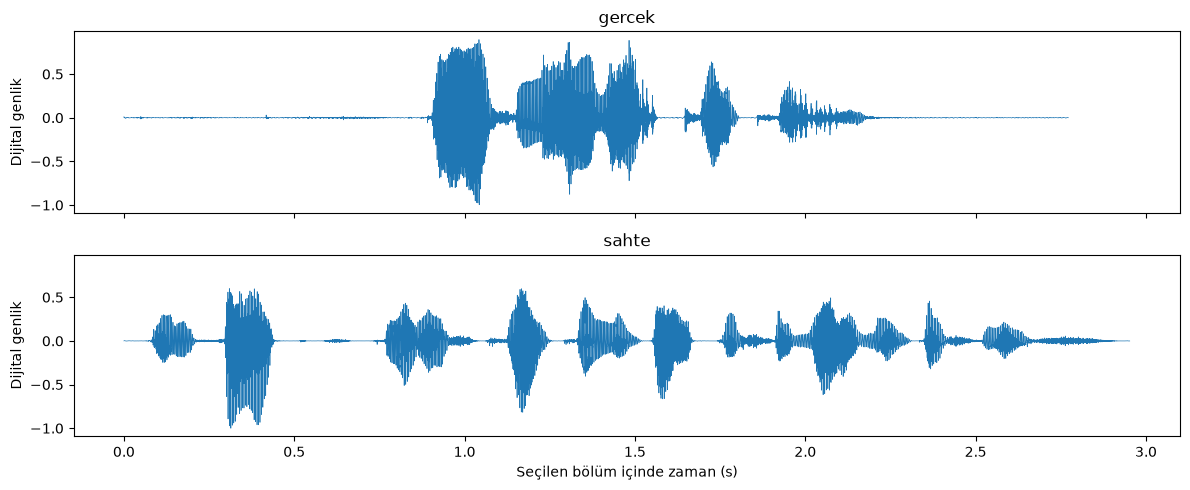

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True, sharey=True)
for ax, (etiket, y) in zip(axes, VERI.items()):
    ax.plot(np.arange(len(y))/SR, y, linewidth=.5)
    ax.set(title=etiket, ylabel='Dijital genlik')
axes[-1].set_xlabel('Seçilen bölüm içinde zaman (s)')
fig.tight_layout()
fig.savefig(OUT/'dalga_bicimleri.png', dpi=160)
plt.show()

## Üç gösterimi hesapla
STFT ve Mel güç, CQT genlik üzerinden dB'ye dönüştürülür. Her satırın referansı o dönüşüm için **iki dosyanın ortak maksimumudur**; her dosyayı ayrı normalize etmiyoruz.
CQT, logaritmik frekans aralıklarıyla harmonik yapıyı incelemeye yardımcı olur; 65 Hz altını bu ayarla göstermez.

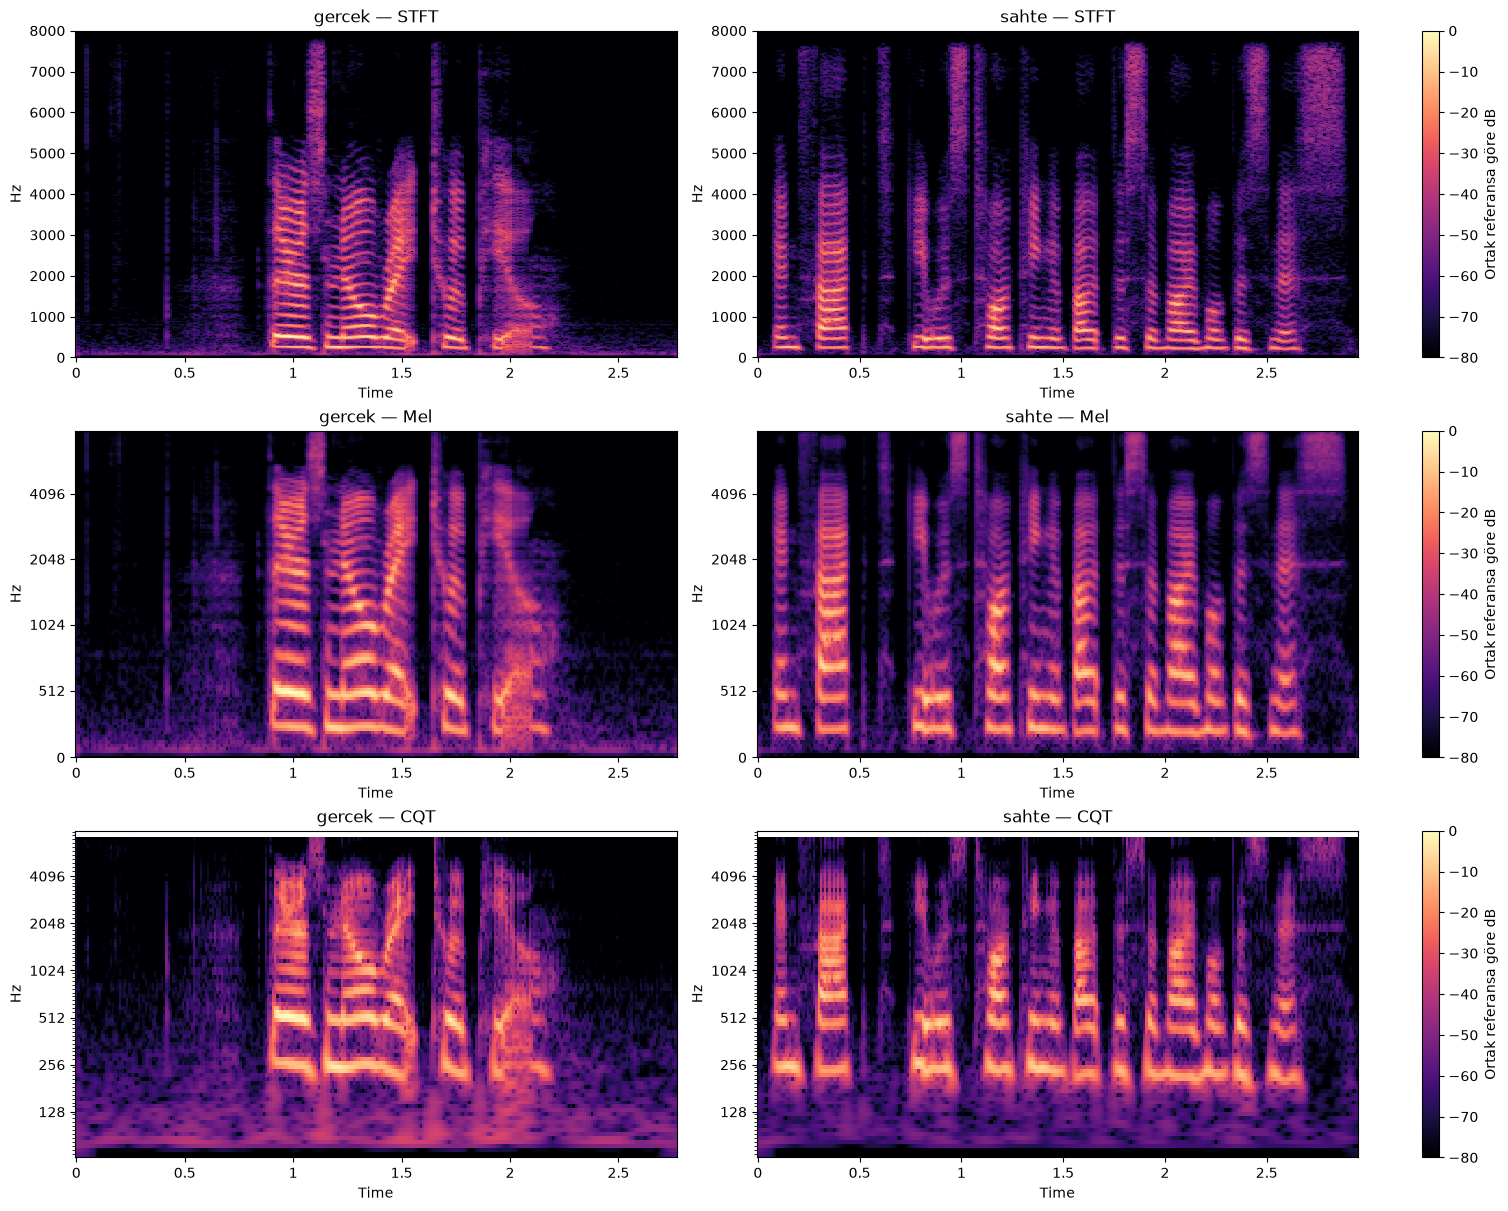

Çıktı: /Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/outputs/figures/karsilastirma/20261011_213833_693820


In [6]:
N_BINS = int(np.floor(BINS_PER_OCTAVE * np.log2((FMAX*.9)/FMIN_CQT))) + 1
DONUSUMLER = {}
for etiket, y in VERI.items():
    stft = np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP))**2
    mel = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT,
        hop_length=HOP, n_mels=N_MELS, fmax=FMAX, power=2)
    cqt = np.abs(librosa.cqt(y, sr=SR, hop_length=HOP,
        fmin=FMIN_CQT, n_bins=N_BINS, bins_per_octave=BINS_PER_OCTAVE))
    DONUSUMLER[etiket] = {'STFT':stft, 'Mel':mel, 'CQT':cqt}

fig, axes = plt.subplots(3, 2, figsize=(15, 12), layout='constrained')
for row, tur in enumerate(['STFT', 'Mel', 'CQT']):
    ref = max(1e-12, max(d[tur].max() for d in DONUSUMLER.values()))
    for col, etiket in enumerate(VERI):
        matrix = DONUSUMLER[etiket][tur]
        db = (librosa.amplitude_to_db(matrix, ref=ref, top_db=None) if tur=='CQT'
              else librosa.power_to_db(matrix, ref=ref, top_db=None))
        extra = ({'y_axis':'linear'} if tur=='STFT' else
                 {'y_axis':'mel', 'fmax':FMAX} if tur=='Mel' else
                 {'y_axis':'cqt_hz', 'fmin':FMIN_CQT, 'bins_per_octave':BINS_PER_OCTAVE})
        img = librosa.display.specshow(db, sr=SR, hop_length=HOP,
            x_axis='time', ax=axes[row,col], cmap='magma', vmin=-80, vmax=0, **extra)
        axes[row,col].set(title=f'{etiket} — {tur}', ylim=(FMIN_CQT if tur=='CQT' else 0, FMAX))
    fig.colorbar(img, ax=axes[row,:].tolist(), label='Ortak referansa göre dB')
fig.savefig(OUT/'stft_mel_cqt.png', dpi=160)
plt.show()
save_json(OUT/'ayarlar.json', dict(files=BILGI, sr=SR, n_fft=N_FFT, hop=HOP,
    n_mels=N_MELS, fmax=FMAX, cqt_fmin=FMIN_CQT, cqt_bins=N_BINS,
    bins_per_octave=BINS_PER_OCTAVE, normalization=False))
print('Çıktı:', OUT)

## İnceleme notları
Harmonik süreklilik, konuşma geçişleri, yüksek frekans kesilmesi ve sessiz aralıklardaki enerjiye bakın.
Metin/konuşmacı/codec/cihaz farklarını not edin. Bir görüntü farkını doğrudan sahte ses belirtisi saymayın.

Kaynaklar: [Mel](https://librosa.org/doc/main/api/generated/librosa.feature.melspectrogram.html), [CQT](https://librosa.org/doc/main/api/generated/librosa.cqt.html).